In [1]:
%pip install opencv-python
%pip install kmedoids


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path ## Rutas relativas
from PIL import Image  ## Abrir y manipular imagenes 
from sklearn.cluster import KMeans ##
from sklearn.metrics import silhouette_score
import numpy as np ### Procesar Matrices - Valores de pixeles
import matplotlib.pyplot as plt ## Graficar
import cv2
import pandas as pd
from sklearn.manifold import TSNE
import kmedoids

1. Recopilación de un conjunto diverso de imágenes en diferentes estilos artísticos (al menos tres estilos o pintores), a partir del repositorio. Al comienzo del notebook se deben mostrar las imágenes seleccionadas (entre 6 – 10 imágenes), explicando, de manera breve, la motivación para su selección.

## Selección de las imágenes**

Para armar el conjunto de imágenes (10) no se aplicó ningún criterio de selección formal ni se buscó una caracterización particular de las obras. La elección fue en buena medida aleatoria, pero orientada por un objetivo: que la muestra fuera variada.

En lugar de escoger obras parecidas entre sí, se buscaron opciones con diferentes técnicas de pintado, paletas de color y estilos, incluyendo trabajos que no corresponden a pintura tradicional. La intención era que el conjunto no estuviera sesgado hacia un solo tipo de imagen, de modo que las decisiones sobre el preprocesamiento y sobre el número de colores no dependieran de las particularidades de una sola clase de obra y pudieran sostenerse frente a imágenes distintas.

**Abrir las imagenes**

In [3]:
def cargar_imagen(image_dir):
    
    image_paths = sorted(
        path for path in image_dir.glob("*")
        if path.is_file()
    )
    print(f"Cant. de imagenes: {len(image_paths)}")
    return image_paths

| Vista previa | Autor | Obra | Año | Tamaño original |
|:---:|---|---|:---:|:---:|
| <img src="data/images/albert-gleizes_femme-cubiste-1921.jpg" width="110"> | Albert Gleizes | Femme cubiste | 1921 | 1382 × 1889 |
| <img src="data/images/alberto-magnelli_the-drunk-man-1914.jpg" width="110"> | Alberto Magnelli | The Drunk Man | 1914 | 1382 × 1859 |
| <img src="data/images/aldemir-martins_baiana-1980.jpg" width="110"> | Aldemir Martins | Baiana | 1980 | 1382 × 1845 |
| <img src="data/images/aldo-mondino_collage-1973.jpg" width="110"> | Aldo Mondino | Collage | 1973 | 1382 × 1742 |
| <img src="data/images/aleksey-savrasov_early-spring-2.jpg" width="110"> | Aleksey Savrasov | Early Spring | — | 1880 × 1382 |
| <img src="data/images/alvaro-lapa_c-line-s-notebook-1990.jpg" width="110"> | Álvaro Lapa | Céline's Notebook | 1990 | 3300 × 1382 |
| <img src="data/images/marjorie-strider_green-triptych-1963.jpg" width="110"> | Marjorie Strider | Green Triptych | 1963 | 1905 × 1382 |
| <img src="data/images/red-grooms_dali-salad-ii-1980.jpg" width="110"> | Red Grooms | Dalí Salad II | 1980 | 1403 × 1382 |
| <img src="data/images/richard-artschwager_logus-blue-logus-1967.jpg" width="110"> | Richard Artschwager | Logus Blue Logus | 1967 | 1382 × 1951 |
| <img src="data/images/yayoi-kusama_fields-in-spring-1988.jpg" width="110"> | Yayoi Kusama | Fields in Spring | 1988 | 1382 × 1629 |

## Preprocesar las imagenes


2. Preparación de los datos, justificando las decisiones tomadas.

In [4]:
def tamano_original(image_paths):
    
    for path in image_paths:
        if path.is_file():
            image = cv2.imread(str(path))
            height, width = image.shape[:2]
            print(f"{path.name}: tamaño={width} × {height}")

**Transformacion RGB**

Se incorporó la conversión de BGR a RGB debido a que cv2.imread() carga las imágenes en formato BGR. Esto garantiza una representación RGB consistente antes de realizar el redimensionamiento y la extracción de la paleta mediante K-Means.

In [5]:
def convert_to_rgb(image):
    
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image_rgb

**Redimensionamiento de las imágenes**

Las imágenes seleccionadas tienen dimensiones variables, por ejemplo, `3300 × 1382` y `1382 × 1629`. Por esta razón, se realizará un proceso de redimensionamiento (*resize*) antes de utilizarlas en el modelo.

No se utilizará un tamaño fijo para todas las imágenes, ya que esto podría cambiar su relación de aspecto y generar deformaciones. En su lugar, se establecerá un tamaño máximo y cada imagen se redimensionará manteniendo su proporción original.

El objetivo del redimensionamiento es **reducir el número de píxeles que se deben procesar**, haciendo que el algoritmo sea más rápido y requiera menos recursos, pero conservando la información de color de las obras.

Aunque en este ejercicio se trabaja con un número reducido de imágenes, algunas de ellas tienen millones de píxeles. Además, el pipeline debe estar preparado para recibir imágenes nuevas que podrían tener una resolución mucho mayor. Por esta razón, se incluye el redimensionamiento como parte del preprocesamiento, buscando reducir el costo computacional sin perder información relevante para la extracción de la paleta de colores.



**Decisión sobre el factor de reducción**


En lugar de establecer un tamaño fijo para todas las imágenes, se decidió evaluar diferentes **factores de reducción**. Esta decisión permite mantener la proporción original de cada imagen y, al mismo tiempo, analizar cómo la reducción del número de píxeles afecta la información de color y el costo computacional del procesamiento con K-Means. Se probarán los factores **1, 1/2, 1/3, 1/4, 1/8, 1/16 y 1/32**, donde cada factor se aplica tanto al ancho como al alto de la imagen. De esta forma, la selección del factor final no se realizará de manera arbitraria, sino a partir de la comparación de los resultados obtenidos en términos de conservación de la información y eficiencia computacional.


In [6]:
## Definir la funcion para 
## Calcular los nuevos tama;os segun el factor para redimensionar.
## Redimensionar usando el metodo del area

RESIZE_FACTORS = [1, 1/2, 1/3, 1/4, 1/8, 1/16, 1/32]

def resize_area(image, factor):
    
    height, width = image.shape[:2]
    new_width = int(width * factor)
    new_height = int(height * factor)
    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )
    return resized

Se incluye el factor 1, correspondiente a la imagen original sin reducción, como referencia para evaluar el efecto de los distintos niveles de redimensionamiento. De esta manera, las paletas obtenidas a partir de cada tamaño reducido pueden compararse con la paleta de la imagen original y determinar qué factor permite reducir el número de píxeles manteniendo una representación de color suficientemente similar.

**Reshape y normalizacion**

Posteriormente, las imágenes se transforman mediante un reshape para representar cada píxel como una observación independiente con tres componentes RGB. Finalmente, los valores de los píxeles se normalizan al rango [0,1], dejando los datos en una estructura adecuada para aplicar K-Means.

In [7]:
def flatten_and_normalize(image):

    image = image.reshape((-1, 3))
    image = image / 255.0
    return image

3. Construcción del pipeline de preparación de datos.

### Pipeline Preprocesamiento

In [8]:
def preprocesamiento(image_paths, resize_factors):

    processed_images = []

    for path in image_paths:

        # Cargar imagen
        image = cv2.imread(str(path))

        # Convertir a RGB
        image = convert_to_rgb(image)

        # Aplicar cada factor de reducción
        for factor in resize_factors:

            # Resize con AREA
            resized = resize_area(image, factor)

            # Reshape y normalización
            processed = flatten_and_normalize(resized)

            processed_images.append({
                "path": path,
                "factor": factor,
                "image": processed,
                "shape": resized.shape,
                "resized": resized
            })

    return processed_images

## Preparacion de las imagenes

In [9]:
IMAGE_DIR = Path("data/images")

image_paths = cargar_imagen(IMAGE_DIR)

processed_images = preprocesamiento(
    image_paths,
    RESIZE_FACTORS
)

Cant. de imagenes: 10


4. Construcción del modelo de agrupación con el algoritmo seleccionado con búsqueda de hiperparámetros, validándolo con medidas de evaluación adecuadas. Se justifica la selección del algoritmo y las métricas empleadas. Importante: el número de grupos debe ajustarse a las características de las imágenes, es un valor que varía, no es fijo. Es decir, el método debe construir un modelo de agrupación para cada imagen de entrada.

## Experimiento para seleccion del factor de redimensionamiento y algoritmo

El experimento que hicimos buscaba determinar qué factor de redimensionamiento permite reducir el tamaño de las imágenes sin afectar significativamente la calidad del agrupamiento de colores.

Primero, se tomaron las imágenes originales y se generaron diferentes versiones redimensionadas utilizando los factores 1, 1/2, 1/3, 1/4, 1/8, 1/16 y 1/32. Para cada versión, los píxeles de la imagen se representaron mediante sus valores de color RGB y se aplicó K-Means probando diferentes cantidades de clústeres, desde \(k=2\) hasta \(k=10\). Para cada valor de \(k\) se calculó el coeficiente de silueta, con el objetivo de evaluar qué tan cohesionados y separados estaban los grupos de colores. Posteriormente, para cada imagen y factor de redimensionamiento, se tomó el valor máximo del coeficiente de silueta, correspondiente al \(k\) que proporcionaba el mejor agrupamiento. Finalmente, se compararon estos valores entre los diferentes factores. 

**Selección del número de clústeres: coeficiente de silueta en lugar del método del codo**

Para determinar el número de clústeres se optó por el coeficiente de silueta y no por el método del codo. La razón principal es que el método del codo exige una interpretación visual de la curva: hay que identificar a ojo el punto donde cambia la pendiente, y ese punto suele ser ambiguo, especialmente con datos de píxeles, donde la inercia disminuye de forma suave y continua sin formar un quiebre evidente. Esto haría que la elección de (k) dependiera del criterio de quien observa la gráfica y no de un valor comparable entre imágenes.

El coeficiente de silueta, en cambio, entrega un valor numérico para cada (k), lo que permite seleccionar el número de clústeres de manera objetiva tomando simplemente el valor más alto. Además mide algo más completo que la inercia: no solo qué tan cohesionados están los píxeles dentro de su grupo, sino también qué tan separados están de los demás grupos.

**Elección entre K-Means y K-Medoids**

Para comparar ambos algoritmos, se repitió el procedimiento de evaluación de K-Medoids para los mismos factores de redimensionamiento utilizados con K-Means. La diferencia entre ambos está en el punto que representa a cada grupo: K-Means utiliza el centroide, que es el color promedio de los píxeles del clúster, mientras que K-Medoids utiliza el medoide, que es un píxel real de la imagen.

## K-Means

Para determinar el número óptimo de clústeres, se implementó un procedimiento basado en K-Means, evaluando diferentes valores de k, desde 2 hasta 10, para cada imagen y factor de redimensionamiento. Para cada valor de k, se calculó el coeficiente de silueta, utilizando este indicador para evaluar la calidad del agrupamiento. Posteriormente, se seleccionó como k óptimo aquel valor que presentó el mayor coeficiente de silueta. Finalmente, los resultados se representaron gráficamente para analizar el comportamiento del coeficiente de silueta en función del número de clústeres y del factor de redimensionamiento.

In [10]:
## Definir la funcion para calcular el coeficiente y graficarlo
def silhouette_plot_kmeans(X, k_min=2, k_max=10, sample_size=5000,
                    random_state=0, factor=None, nombre=None):
   
    siluetas = []
    n_muestra = min(sample_size, len(X))

    for i in range(k_min, k_max+1):
        model_k = KMeans(n_clusters=i, max_iter=300, n_init=10, random_state=random_state)
        etiquetas = model_k.fit_predict(X)
        siluetas.append(silhouette_score(X, etiquetas,
                                         sample_size=n_muestra,
                                         random_state=random_state))
    
    k_optimo = range(k_min, k_max+1)[int(np.argmax(siluetas))]

    if not hasattr(silhouette_plot_kmeans, "contador") or silhouette_plot_kmeans.contador == 0:
        silhouette_plot_kmeans.contador = 0
        silhouette_plot_kmeans.fig, silhouette_plot_kmeans.axes = plt.subplots(1, 7, figsize=(21, 5))
        silhouette_plot_kmeans.fig.suptitle(f'Imagen: {nombre}', fontsize=16)
        
    ax = silhouette_plot_kmeans.axes[silhouette_plot_kmeans.contador]
    
    ax.plot(range(k_min, k_max+1), siluetas, marker='o')
    ax.axvline(k_optimo, color='red', linestyle='--', label=f'k óptimo = {k_optimo}')
    ax.set_title(f'Factor = {factor:g}')
    ax.set_xlabel('Número de clústeres')
    ax.set_ylabel('Coeficiente de silueta')
    ax.grid()
    ax.legend()
    
    silhouette_plot_kmeans.contador += 1
    
    if silhouette_plot_kmeans.contador == 7:
        plt.tight_layout()
        plt.show()
        silhouette_plot_kmeans.contador = 0

    return siluetas, k_optimo

Calcular los coeficientes de Silhouette para todas la imagenes

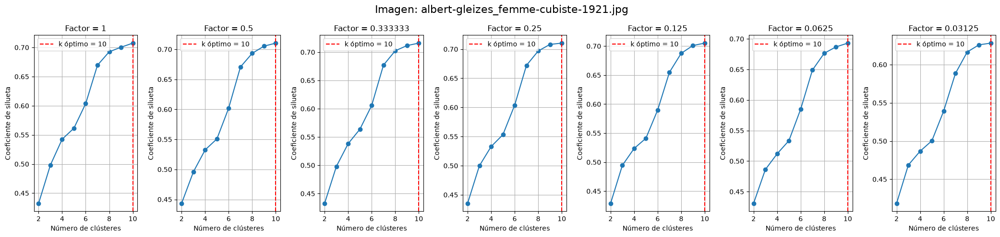

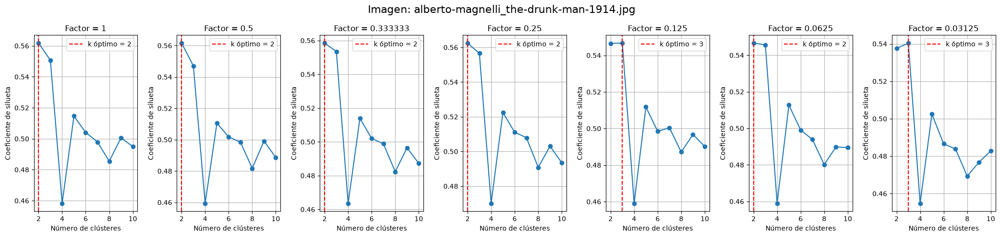

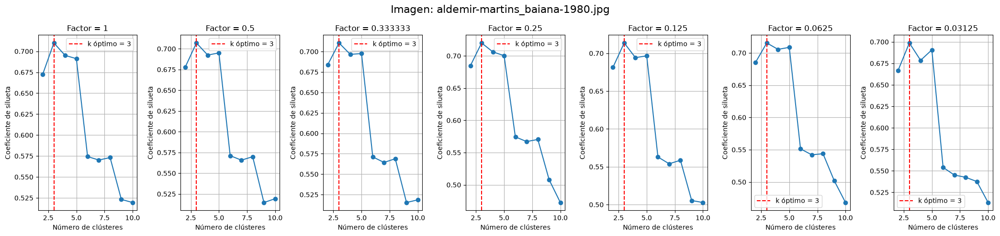

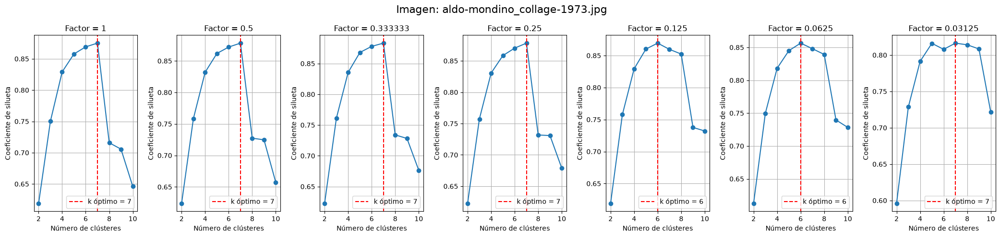

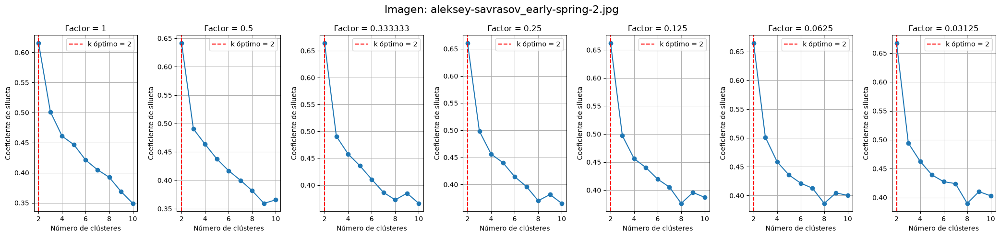

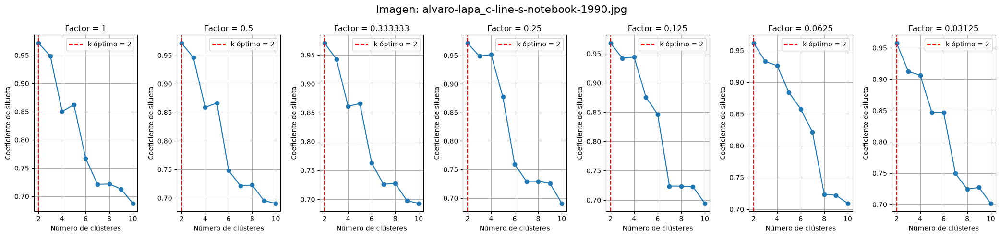

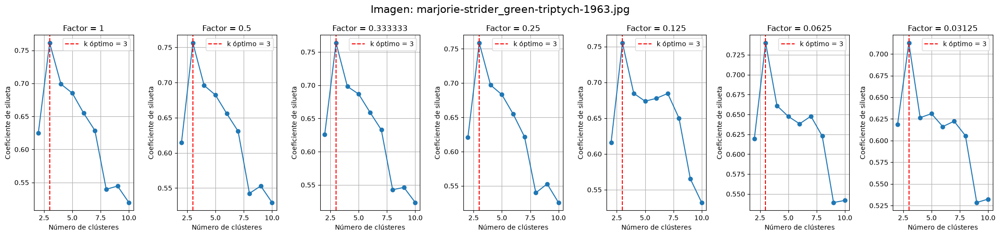

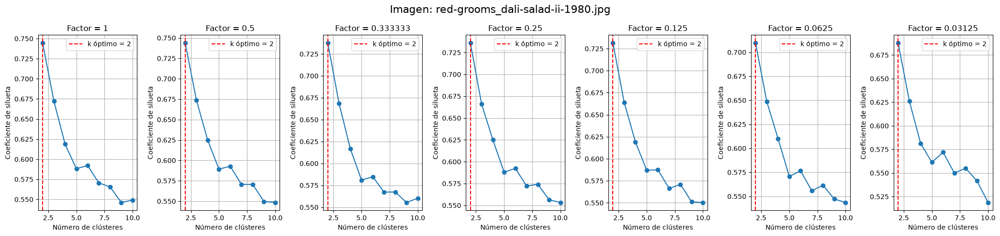

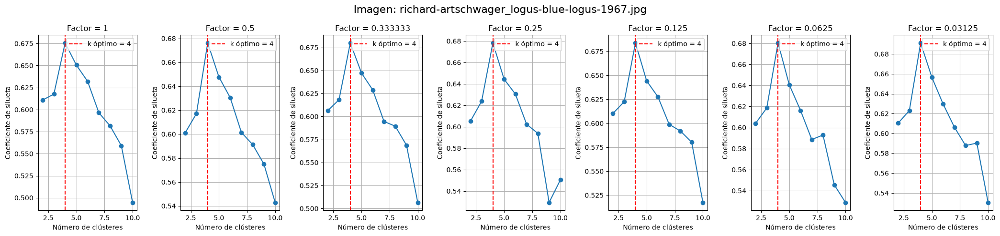

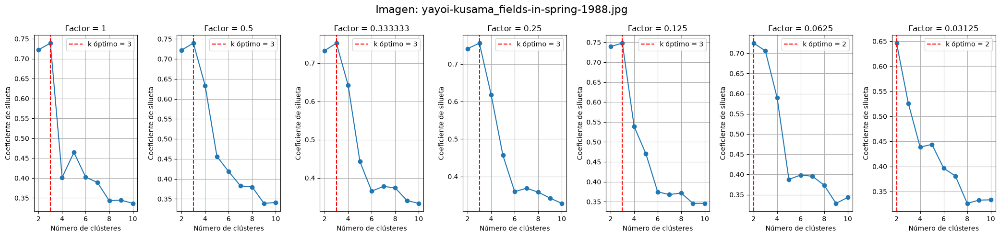

In [11]:
resultados_kmeans = []

for item in processed_images:

    X = item["image"]
    
    siluetas, k_optimo = silhouette_plot_kmeans(
    X, 2, 10,
    factor=item["factor"],
    nombre=item["path"].name
    )

    resultados_kmeans.append({
        "path": item["path"].name,
        "factor": item["factor"],
        "siluetas": siluetas,
        "k_optimo": k_optimo
    })

## Ejecutar K-means

Tomamos el k_optimo que encontramos con el coeficiente de silueta, ejecutamos K-Means con ese número de clústeres y guardamos los colores representativos de la imagen.

In [12]:
datos = {(item["path"].name, item["factor"]): item["image"] for item in processed_images}

paletas = []

for r in resultados_kmeans:
    
    X = datos[(r["path"], r["factor"])]

    item = next(i for i in processed_images
                if i["path"].name == r["path"] and i["factor"] == r["factor"])

    modelo = KMeans(n_clusters=r["k_optimo"], max_iter=300, n_init=10, random_state=0)
    etiquetas = modelo.fit_predict(X)

    paletas.append({
        "path": r["path"],
        "factor": r["factor"],
        "colores": modelo.cluster_centers_,
        "etiquetas": etiquetas,
        "shape": item["shape"],
        "resized": item["resized"],
        "k_optimo": r["k_optimo"],
        "modelo": modelo
    })

Imagen original → K-Means → cada píxel recibe un clúster → reemplazamos cada píxel por el color de su centroide → imagen segmentada.

En la siguiente figura se comparan, para cada obra, la imagen original junto con sus siete versiones segmentadas, una por cada factor de reducción. El recorrido se hace una sola vez por imagen, tomando como referencia la versión con factor 1, y a partir de ahí se agrupan las siete versiones de esa misma obra ordenadas de mayor a menor tamaño.

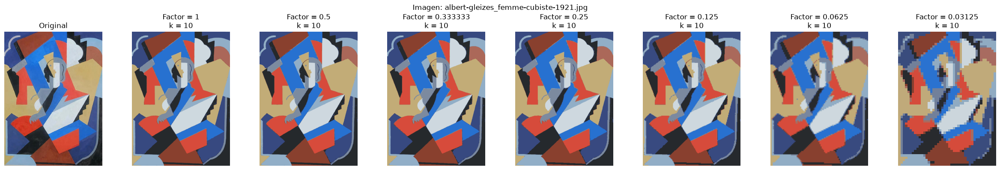

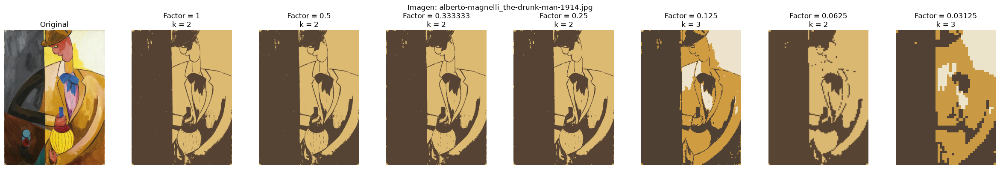

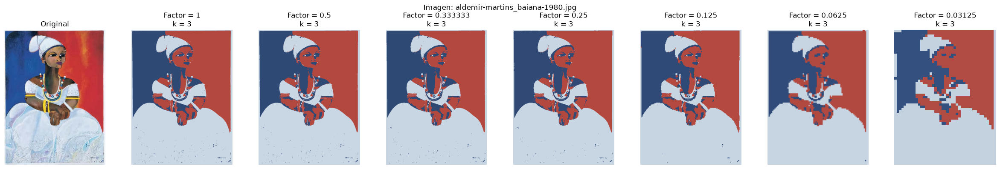

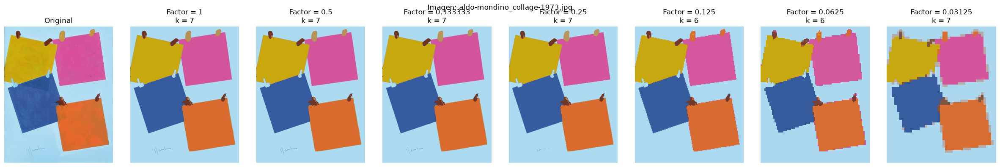

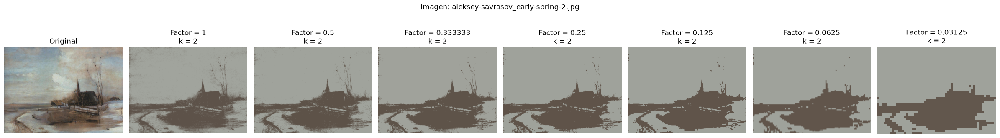

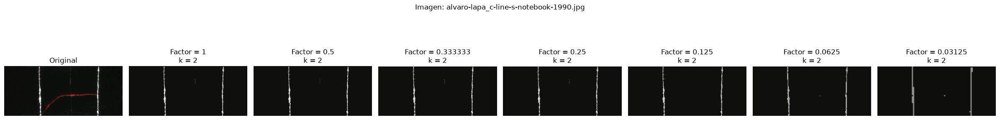

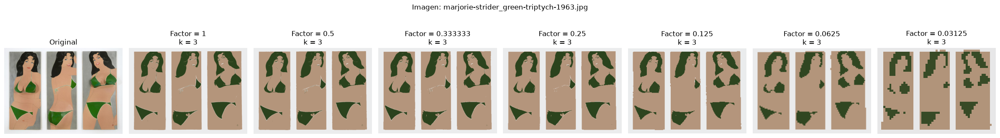

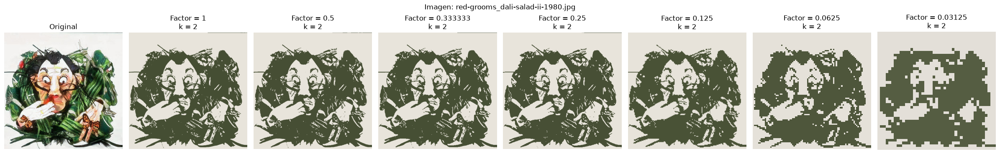

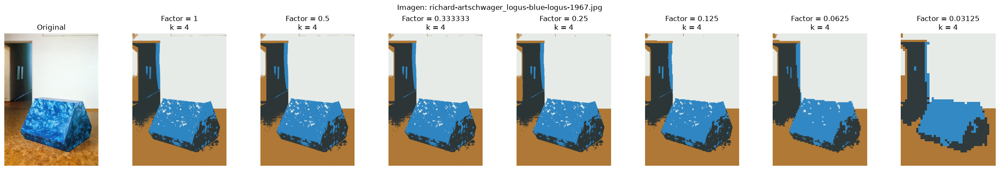

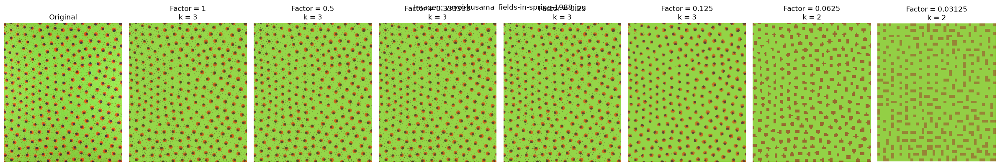

In [13]:
for p in paletas:

    if p["factor"] != 1:
        continue

    plt.figure(figsize=(24, 4))

    nombre = p["path"]

    # Original
    plt.subplot(1, 8, 1)
    plt.imshow(p["resized"])
    plt.title("Original")
    plt.axis("off")

    # 7 factores
    grupo = [q for q in paletas if q["path"] == nombre]
    grupo = sorted(grupo, key=lambda x: x["factor"], reverse=True)

    for i, q in enumerate(grupo):

        centroids = q["colores"]
        labels = q["etiquetas"]

        img_segmentada = (
            centroids[labels] * 255
        ).reshape(q["shape"]).astype(np.uint8)

        plt.subplot(1, 8, i + 2)
        plt.imshow(img_segmentada)
        plt.title(f'Factor = {q["factor"]:g}\nk = {q["k_optimo"]}')
        plt.axis("off")

    plt.suptitle(f"Imagen: {nombre}")
    plt.tight_layout()
    plt.show()

## K-medoides

Como scikit-learn no trae K-Medoids y la librería que sí lo tiene no nos funcionó con la versión de Python que estamos usando, creamos nuestra propia clase para poder hacer la prueba.

La armamos con la misma estructura de K-Means, es decir, recibe los mismos parámetros y devuelve los mismos atributos, para no tener que cambiar nada más del notebook. Por dentro hace dos cosas: primero ajusta el modelo sobre una muestra de 3.000 píxeles, porque K-Medoids necesita calcular la distancia entre todos los pares y con la imagen completa nos quedábamos sin memoria, y después le asigna a cada píxel de la imagen el color del medoide más cercano para que la segmentación quede completa.

In [14]:
class KMedoids:
    """Reemplazo directo de KMeans: mismo constructor, fit_predict y cluster_centers_."""
    def __init__(self, n_clusters=8, max_iter=300, n_init=10, random_state=0,
                 sample_size=3000):
        self.n_clusters, self.max_iter = n_clusters, max_iter
        self.n_init, self.random_state = n_init, random_state
        self.sample_size = sample_size

    @staticmethod
    def _dist(A, B):
        d2 = (A*A).sum(1)[:, None] + (B*B).sum(1)[None, :] - 2.0 * (A @ B.T)
        np.maximum(d2, 0, out=d2)
        return np.sqrt(d2)

    def fit_predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        rng = np.random.default_rng(self.random_state)
        m = min(self.sample_size, len(X))
        Xs = X[rng.choice(len(X), m, replace=False)] if m < len(X) else X
        D = self._dist(Xs, Xs)
        mejor = None
        for s in range(self.n_init):
            r = kmedoids.fasterpam(D, self.n_clusters, max_iter=self.max_iter,
                                   random_state=self.random_state + s)
            if mejor is None or r.loss < mejor.loss:
                mejor = r
        self.cluster_centers_ = Xs[np.asarray(mejor.medoids)]
        self.inertia_ = mejor.loss
        self.labels_ = self._dist(X, self.cluster_centers_).argmin(1)
        return self.labels_

    def fit(self, X):
        self.fit_predict(X); return self

Creamos una función para evaluar la calidad del agrupamiento realizado mediante K-Medoids usando el coeficiente de silueta y determinar automáticamente el número óptimo de clústeres.

In [15]:
## Definir la funcion para calcular el coeficiente y graficarlo
def silhouette_plot(X, k_min=2, k_max=10, sample_size=5000,
                    random_state=0, factor=None, nombre=None):

    siluetas = []
    n_muestra = min(sample_size, len(X))

    for i in range(k_min, k_max+1):
        model_k = KMedoids(n_clusters=i, max_iter=300, n_init=10, random_state=random_state)
        etiquetas = model_k.fit_predict(X)
        siluetas.append(silhouette_score(X, etiquetas,
                                         sample_size=n_muestra,
                                         random_state=random_state))

    k_optimo = range(k_min, k_max+1)[int(np.argmax(siluetas))]

    if not hasattr(silhouette_plot, "contador") or silhouette_plot.contador == 0:
        silhouette_plot.contador = 0
        silhouette_plot.fig, silhouette_plot.axes = plt.subplots(1, 7, figsize=(21, 5))
        silhouette_plot.fig.suptitle(f'Imagen: {nombre}', fontsize=16)

    ax = silhouette_plot.axes[silhouette_plot.contador]

    ax.plot(range(k_min, k_max+1), siluetas, marker='o')
    ax.axvline(k_optimo, color='red', linestyle='--', label=f'k óptimo = {k_optimo}')
    ax.set_title(f'Factor = {factor:g}')
    ax.set_xlabel('Número de clústeres')
    ax.set_ylabel('Coeficiente de silueta')
    ax.grid()
    ax.legend()

    silhouette_plot.contador += 1

    if silhouette_plot.contador == 7:
        plt.tight_layout()
        plt.show()
        silhouette_plot.contador = 0

    return siluetas, k_optimo


Para cada imagen y para cada uno de los factores de redimensionamiento seleccionados, se evaluaron diferentes valores de k mediante el algoritmo K-Medoids. Para cada combinación de imagen, factor y número de clústeres, se calculó el coeficiente de silueta, permitiendo posteriormente identificar el valor de k que presentó el mejor resultado para cada caso.

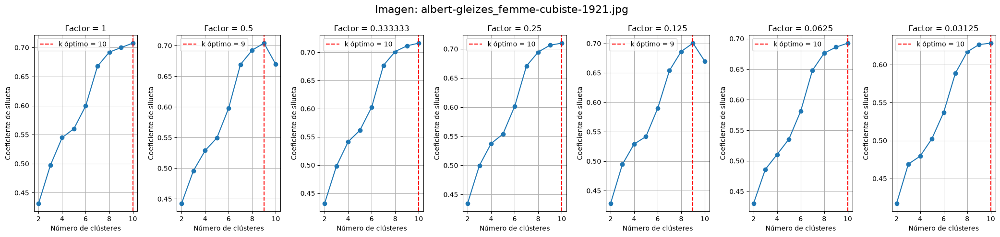

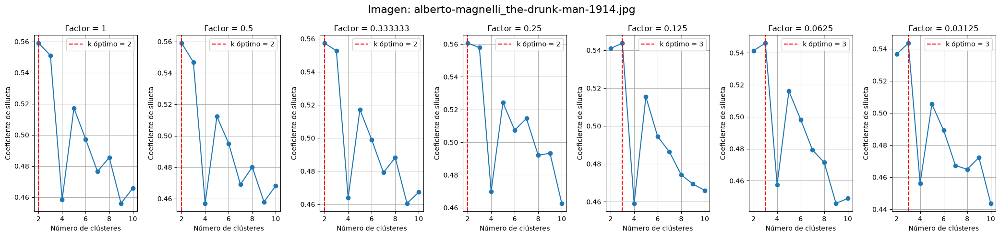

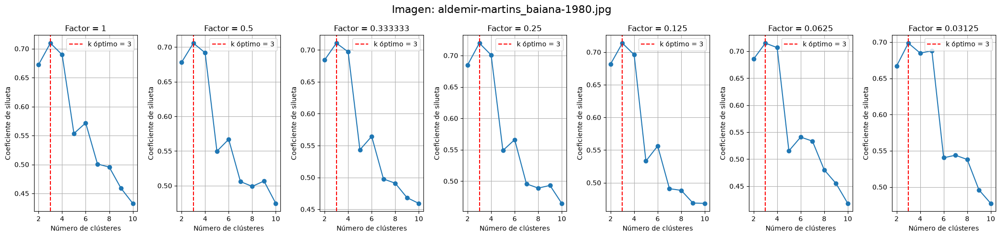

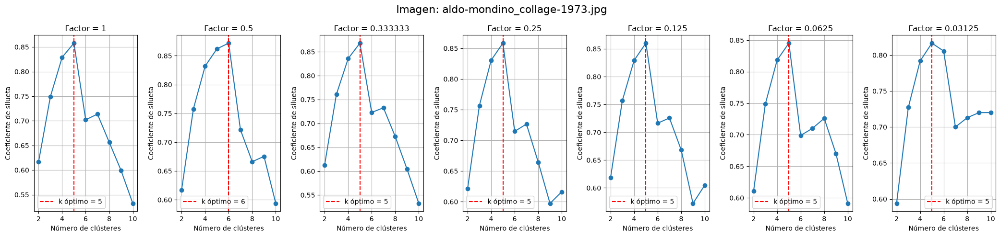

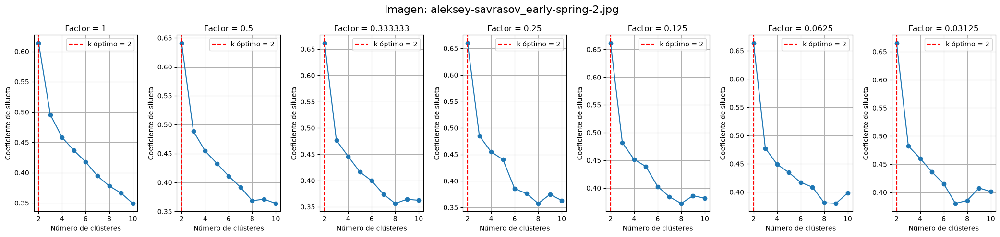

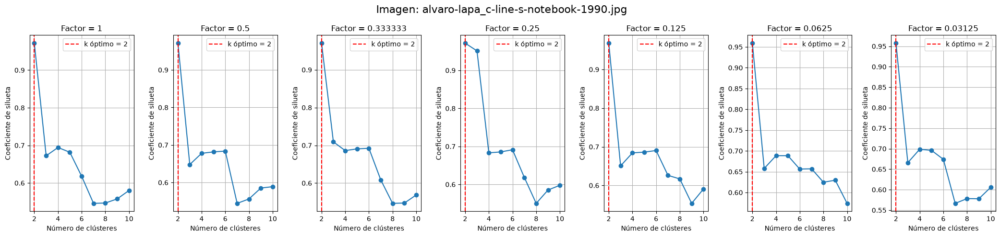

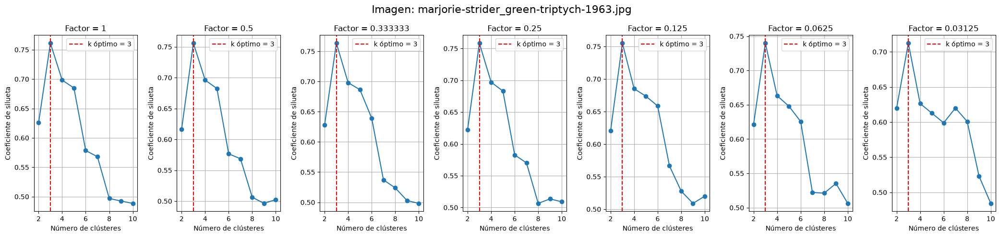

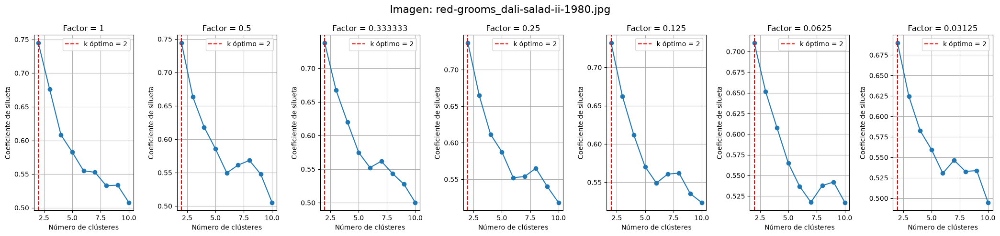

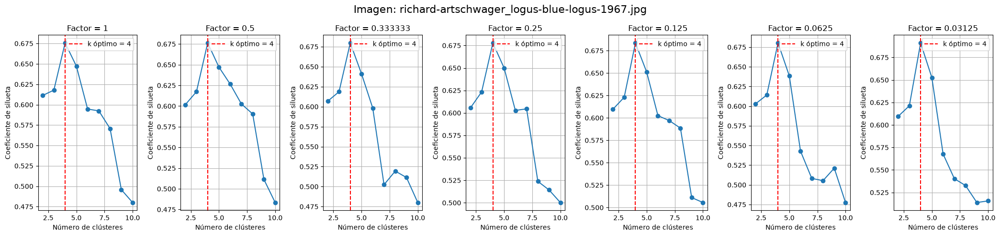

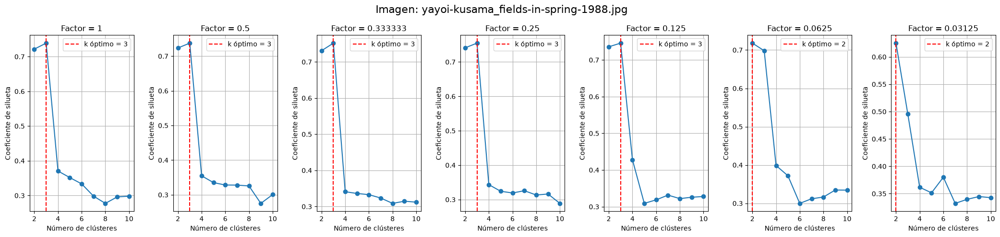

In [16]:
resultados = []

for item in processed_images:

    X = item["image"]
    
    siluetas, k_optimo = silhouette_plot(
    X, 2, 10,
    factor=item["factor"],
    nombre=item["path"].name
    )

    resultados.append({
        "path": item["path"].name,
        "factor": item["factor"],
        "siluetas": siluetas,
        "k_optimo": k_optimo
    })

In [17]:
datos = {(item["path"].name, item["factor"]): item["image"] for item in processed_images}

paletas = []

for r in resultados:
    
    X = datos[(r["path"], r["factor"])]

    item = next(i for i in processed_images
                if i["path"].name == r["path"] and i["factor"] == r["factor"])

    modelo = KMedoids(n_clusters=r["k_optimo"], max_iter=300, n_init=10, random_state=0)
    etiquetas = modelo.fit_predict(X)

    paletas.append({
        "path": r["path"],
        "factor": r["factor"],
        "colores": modelo.cluster_centers_,
        "etiquetas": etiquetas,
        "shape": item["shape"],
        "resized": item["resized"],
        "k_optimo": r["k_optimo"],
        "modelo": modelo
    })

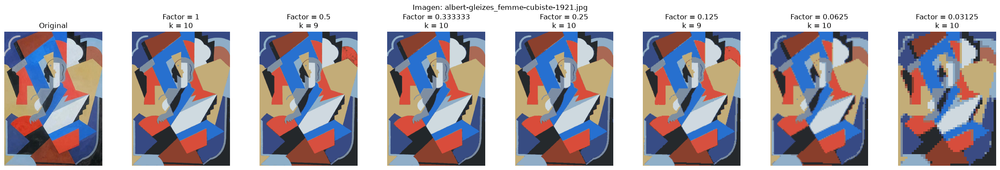

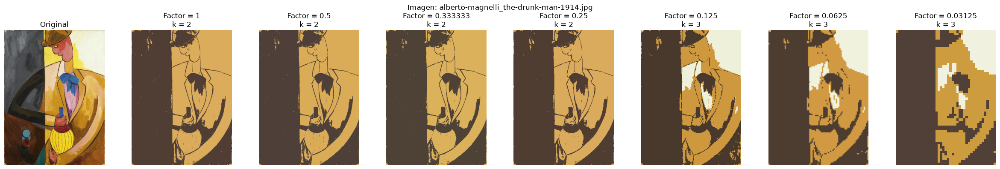

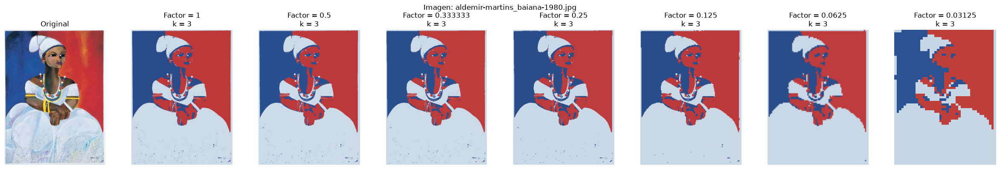

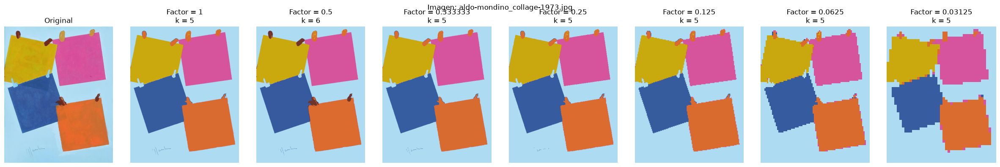

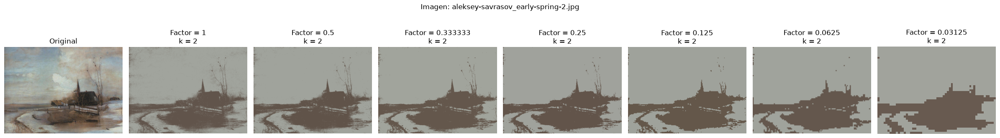

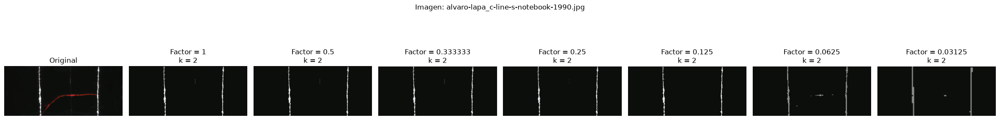

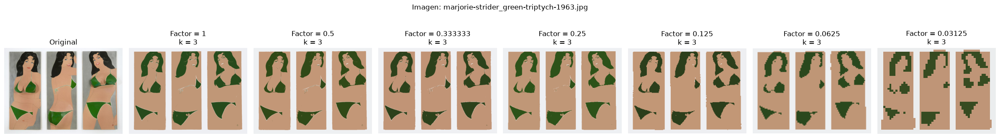

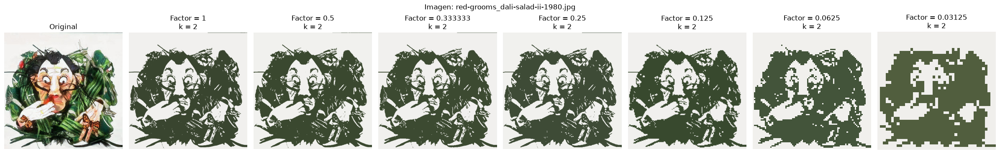

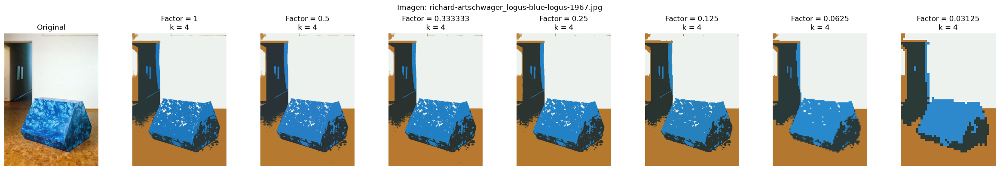

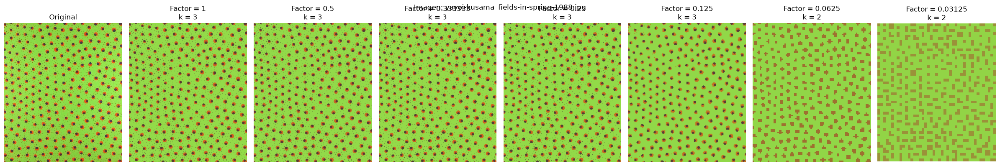

In [18]:
for p in paletas:

    if p["factor"] != 1:
        continue

    plt.figure(figsize=(24, 4))

    nombre = p["path"]

    # Original
    plt.subplot(1, 8, 1)
    plt.imshow(p["resized"])
    plt.title("Original")
    plt.axis("off")

    # 7 factores
    grupo = [q for q in paletas if q["path"] == nombre]
    grupo = sorted(grupo, key=lambda x: x["factor"], reverse=True)

    for i, q in enumerate(grupo):

        centroids = q["colores"]
        labels = q["etiquetas"]

        img_segmentada = (
            centroids[labels] * 255
        ).reshape(q["shape"]).astype(np.uint8)

        plt.subplot(1, 8, i + 2)
        plt.imshow(img_segmentada)
        plt.title(f'Factor = {q["factor"]:g}\nk = {q["k_optimo"]}')
        plt.axis("off")

    plt.suptitle(f"Imagen: {nombre}")
    plt.tight_layout()
    plt.show()

Tomamos el k_optimo que encontramos con el coeficiente de silueta, ejecutamos K-Means con ese número de clústeres y guardamos los colores representativos de la imagen.

## Comparación del coeficiente de silueta entre factores

Esta gráfica resume el experimento: para cada imagen y cada factor se toma el valor máximo del coeficiente de silueta, es decir, el del $k$ óptimo. Cada curva corresponde a un algoritmo y muestra cómo cambia la calidad del agrupamiento a medida que se reduce el tamaño. 

In [22]:
comparacion = []

for r in resultados_kmeans:
    comparacion.append({
        "path": r["path"],
        "factor": r["factor"],
        "algoritmo": "K-Means",
        "silhouette": max(r["siluetas"]),
        "k_optimo": r["k_optimo"]
    })

for r in resultados:
    comparacion.append({
        "path": r["path"],
        "factor": r["factor"],
        "algoritmo": "K-Medoids",
        "silhouette": max(r["siluetas"]),
        "k_optimo": r["k_optimo"]
    })

df_comparacion = pd.DataFrame(comparacion)

estadisticas = (
    df_comparacion
    .groupby(["algoritmo", "factor"])["silhouette"]
    .mean()
    .reset_index(name="media")
)


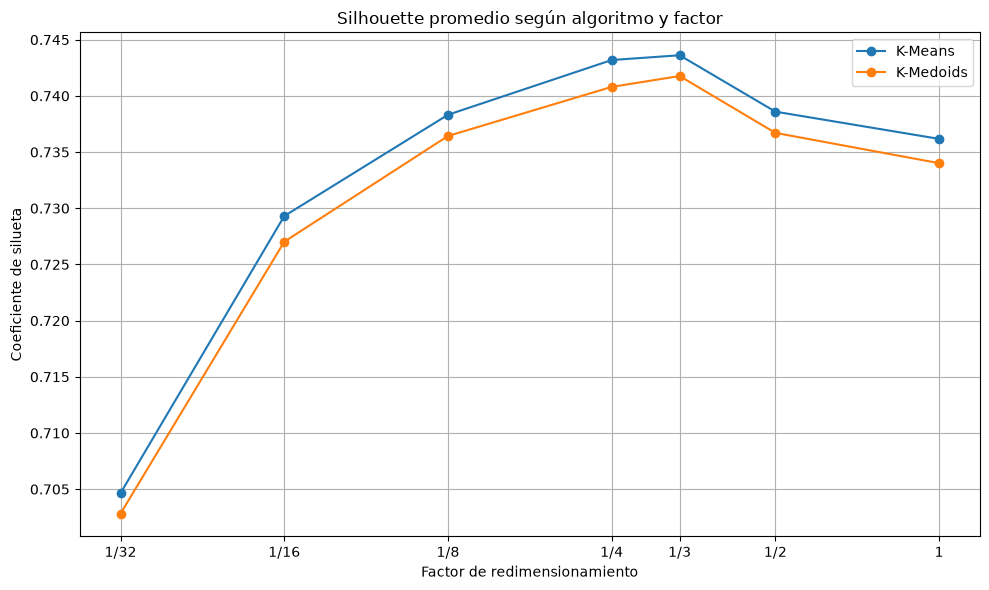

In [23]:
plt.figure(figsize=(10, 6))

for algoritmo, grupo in estadisticas.groupby("algoritmo"):
    grupo = grupo.sort_values("factor")
    
    plt.plot(
        grupo["factor"],
        grupo["media"],
        marker="o",
        label=algoritmo
    )

plt.xscale("log", base=2)

plt.xticks(
    [1/32, 1/16, 1/8, 1/4, 1/3, 1/2, 1],
    ["1/32", "1/16", "1/8", "1/4", "1/3", "1/2", "1"]
)

plt.xlabel("Factor de redimensionamiento")
plt.ylabel("Coeficiente de silueta")
plt.title("Silhouette promedio según algoritmo y factor")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Se seleccionó un factor de redimensionamiento de **1/8**, considerando el equilibrio entre la calidad del agrupamiento y la eficiencia computacional. Aunque los factores 1/2, 1/3 y 1/4 presentan en algunos casos coeficientes de silueta ligeramente superiores, las diferencias con respecto a 1/8 son relativamente pequeñas y, en algunas imágenes, incluso se obtiene un coeficiente mayor con este factor. Por otro lado, utilizar 1/8 permite reducir considerablemente la cantidad de píxeles que deben procesarse y, por tanto, los requerimientos computacionales. Los factores inferiores, como 1/16 y 1/32, sí muestran una disminución más evidente del coeficiente de silueta en varias imágenes.

## K-means después de preprocesar las imágenes con el factor de redimensionamiento de 1/8

Una vez fijado el factor de 1/8, se repite el mismo procedimiento ya descrito, cálculo del coeficiente de silueta, extracción de la paleta con el $k$ óptimo y reconstrucción de la imagen segmentada, esta vez únicamente sobre las imágenes redimensionadas con ese factor.

La diferencia es el rango de $k$: en el experimento anterior se exploró de $k=2$ a $k=10$ para poder comparar los factores entre sí, mientras que aquí se limita de $k=2$ a $k=5$. El objetivo es obtener una paleta representativa de cada obra, y una paleta con demasiados colores deja de cumplir esa función, porque los tonos empiezan a repetirse en variaciones muy cercanas y se pierde la lectura rápida de la composición.

In [24]:
def silhouette_plot(X, k_min=2, k_max=10, sample_size=5000, random_state=0):
   
    siluetas = []
    n_muestra = min(sample_size, len(X))

    for i in range(k_min, k_max+1):
        model_k = KMeans(n_clusters=i, max_iter=300, n_init=10, random_state=random_state)
        etiquetas = model_k.fit_predict(X)
        siluetas.append(silhouette_score(X, etiquetas,
                                         sample_size=n_muestra,
                                         random_state=random_state))
    
    k_optimo = range(k_min, k_max+1)[int(np.argmax(siluetas))]

    plt.plot(range(k_min, k_max+1), siluetas, marker='o')
    plt.axvline(k_optimo, color='red', linestyle='--', label=f'k óptimo = {k_optimo}')
    plt.xlabel('Número de clústeres')
    plt.ylabel('Coeficiente de silueta')
    plt.grid()
    plt.legend()
    plt.show()

    return siluetas, k_optimo

**Cálculo del k óptimo para cada imagen**

Se aplica el coeficiente de silueta únicamente a las imágenes con factor 1/8, probando de $k=2$ a $k=5$. El rango se limita porque una paleta con demasiados colores deja de funcionar como resumen de la obra. Cada imagen recibe su propio $k$, ya que las composiciones de color son distintas entre obras.

Imagen: albert-gleizes_femme-cubiste-1921.jpg | factor: 0.125


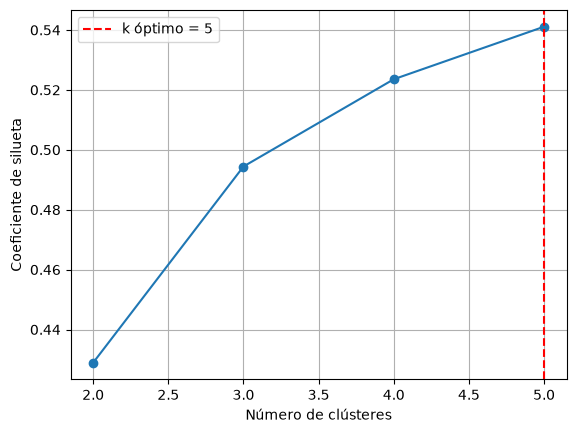

Imagen: alberto-magnelli_the-drunk-man-1914.jpg | factor: 0.125


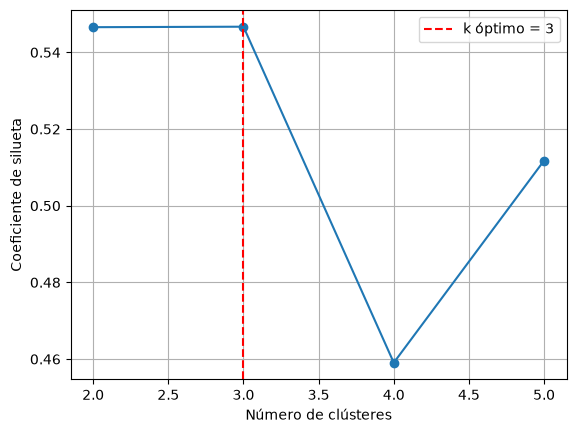

Imagen: aldemir-martins_baiana-1980.jpg | factor: 0.125


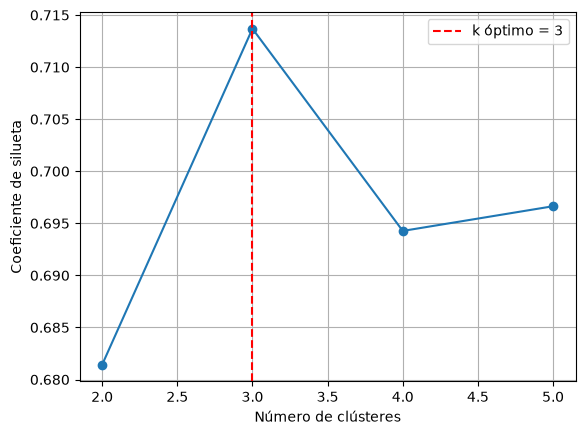

Imagen: aldo-mondino_collage-1973.jpg | factor: 0.125


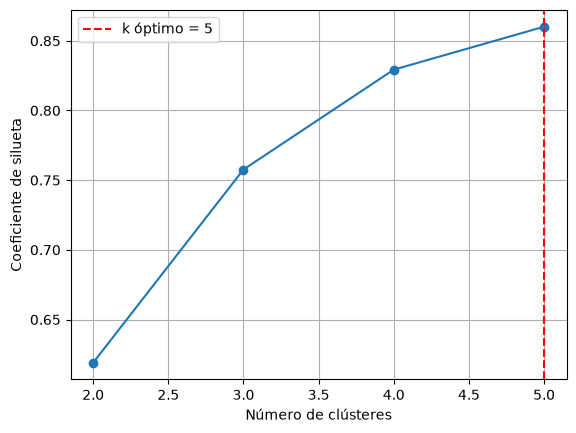

Imagen: aleksey-savrasov_early-spring-2.jpg | factor: 0.125


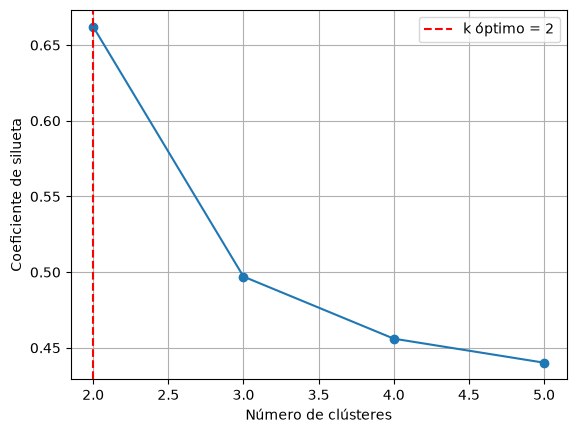

Imagen: alvaro-lapa_c-line-s-notebook-1990.jpg | factor: 0.125


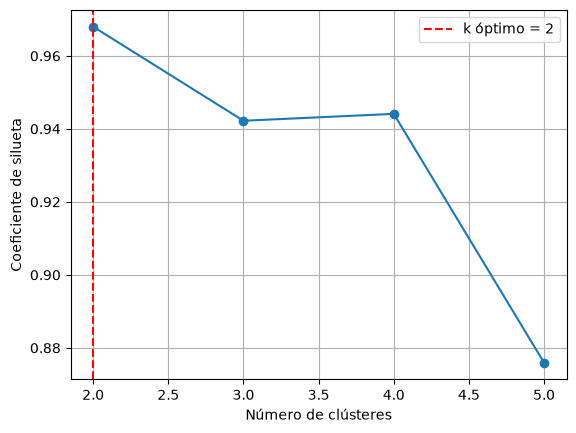

Imagen: marjorie-strider_green-triptych-1963.jpg | factor: 0.125


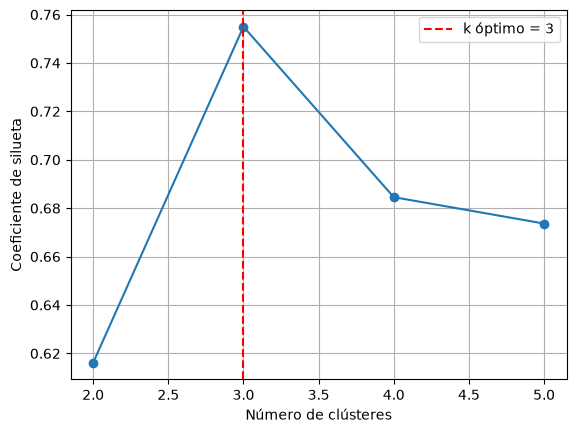

Imagen: red-grooms_dali-salad-ii-1980.jpg | factor: 0.125


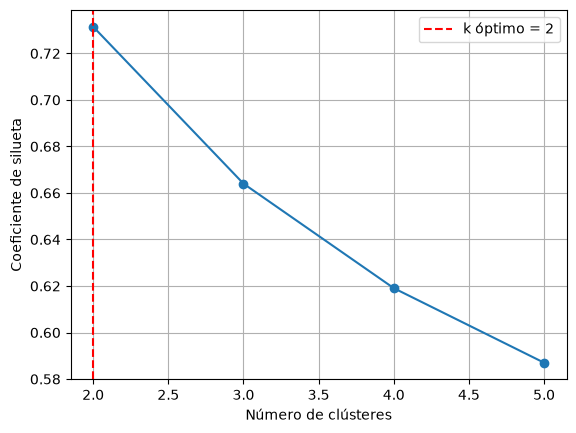

Imagen: richard-artschwager_logus-blue-logus-1967.jpg | factor: 0.125


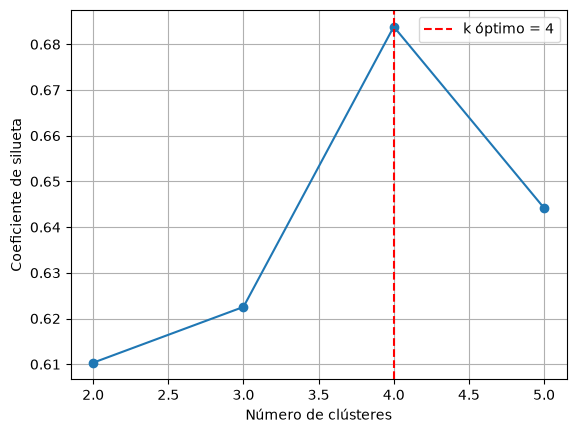

Imagen: yayoi-kusama_fields-in-spring-1988.jpg | factor: 0.125


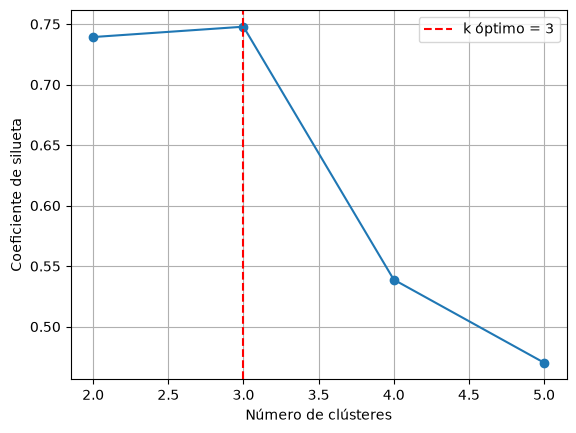

In [25]:
resultados = []

for item in processed_images: ## Procesadas con el pipeline de preprocesamiento inicial
    if item["factor"] != 1/8:## Se eligio este factor despues de probar con varios y notar que la perdida de informacion era minima
        continue

    X = item["image"]

    
    print(f'Imagen: {item["path"].name} | factor: {item["factor"]}')
    siluetas, k_optimo = silhouette_plot(X, 2, 5)

    resultados.append({
        "path": item["path"].name,
        "factor": item["factor"],
        "siluetas": siluetas,
        "k_optimo": k_optimo
    })

**Extracción de la paleta**

Con el $k$ óptimo de cada imagen se ajusta K-Means una última vez. De ahí salen los dos elementos que necesita el proyecto: los centroides, que son los colores de la paleta, y las etiquetas, que indican a qué color pertenece cada píxel.

In [26]:
datos = {(item["path"].name, item["factor"]): item["image"] for item in processed_images}

paletas = []

for r in resultados:
    
    X = datos[(r["path"], r["factor"])]

    item = next(i for i in processed_images
                if i["path"].name == r["path"] and i["factor"] == r["factor"])

    modelo = KMeans(n_clusters=r["k_optimo"], max_iter=300, n_init=10, random_state=0)
    etiquetas = modelo.fit_predict(X)

    paletas.append({
        "path": r["path"],
        "factor": r["factor"],
        "colores": modelo.cluster_centers_,
        "etiquetas": etiquetas,
        "shape": item["shape"],
        "resized": item["resized"],
        "k_optimo": r["k_optimo"],
        "modelo": modelo
    })

**Imagen original frente a imagen segmentada**

Cada píxel se reemplaza por el color del centroide al que fue asignado y se recupera la forma de la imagen. Sirve para verificar si el número de colores elegido alcanza para representar la obra.

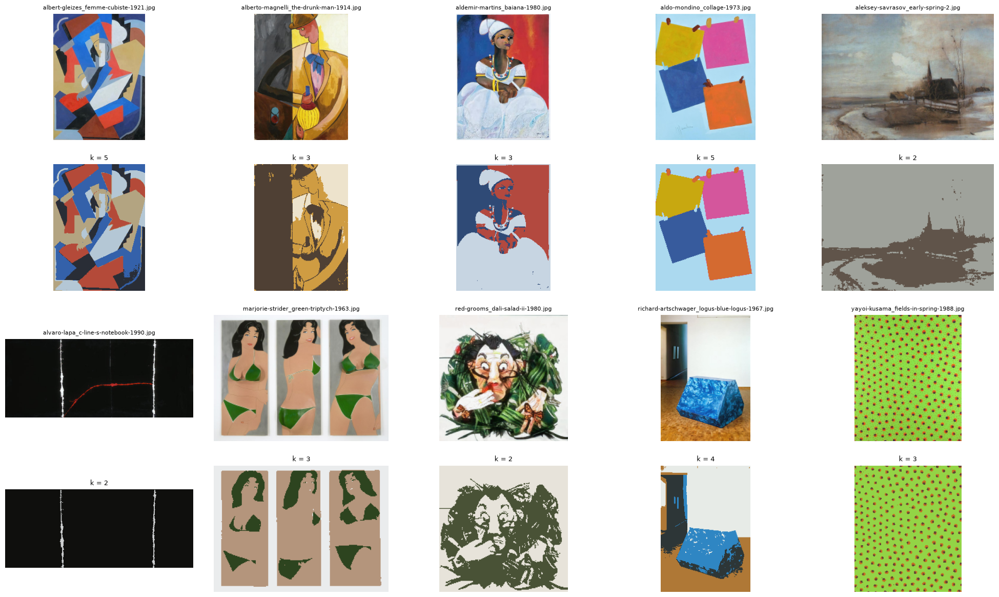

In [27]:
fig, ax = plt.subplots(4, 5, figsize=(20, 12))

for i, p in enumerate(paletas):

    centroids = p["colores"]
    labels = p["etiquetas"]
    target_shape = p["shape"]
    img_original = p["resized"]

    img_segmentada = (
        centroids[labels] * 255
    ).reshape(target_shape).astype(np.uint8)

    fila = (i // 5) * 2
    columna = i % 5

    # Original
    ax[fila, columna].imshow(img_original)
    ax[fila, columna].set_title(
        f'{p["path"]}',
        fontsize=8
    )
    ax[fila, columna].axis("off")

    # Segmentada
    ax[fila + 1, columna].imshow(img_segmentada)
    ax[fila + 1, columna].set_title(
        f'k = {p["k_optimo"]}',
        fontsize=9
    )
    ax[fila + 1, columna].axis("off")

plt.tight_layout(pad=2)
plt.show()

## Muestrario representativo

5. Construcción de la función que transforma los grupos de colores identificados en un muestrario representativo

In [28]:
def crear_muestrario(colores, nombre):
    plt.figure(figsize=(10, 2))

    for i, color in enumerate(colores):
        plt.subplot(1, len(colores), i + 1)
        plt.imshow([[color]])
        plt.title(f"Clúster {i+1}")
        plt.axis("off")

    plt.suptitle(f"Muestrario de colores - {nombre}")
    plt.tight_layout()
    plt.show()

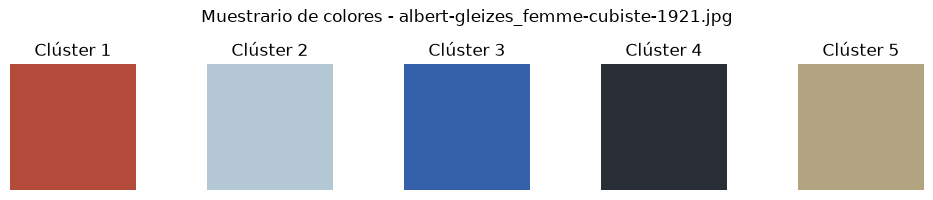

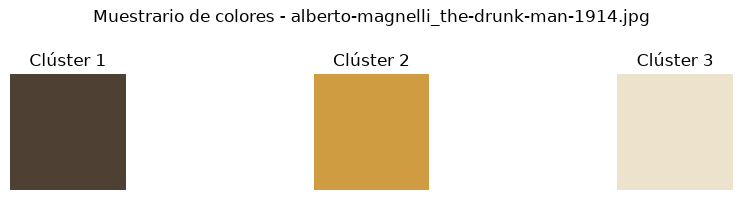

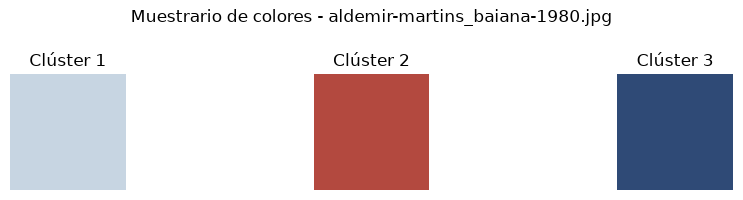

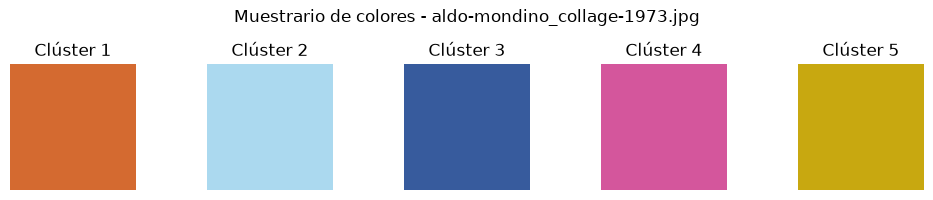

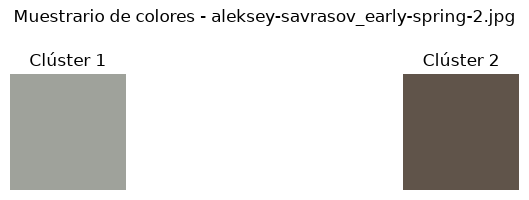

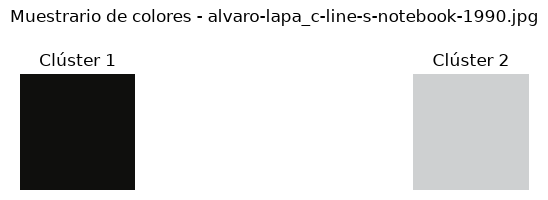

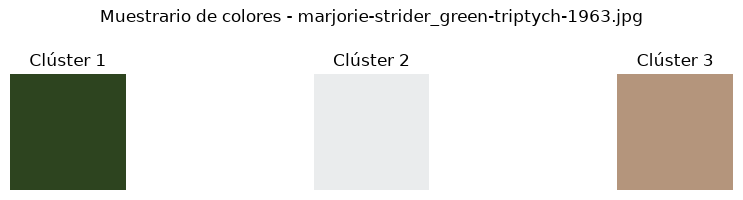

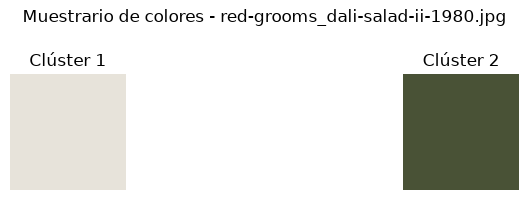

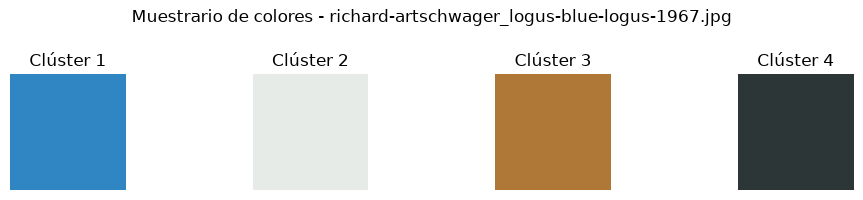

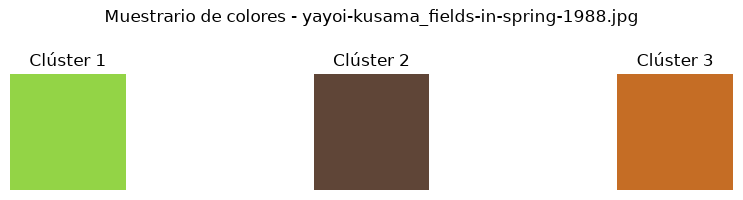

In [29]:
for p in paletas:
    crear_muestrario(p["colores"], p["path"])

## t-SNE

t-SNE solamente transforma los píxeles RGB a dos dimensiones para poder representar visualmente su distribución. 


t-SNE no vuelve a agrupar los colores. K-Means ya hizo esa agrupación.

In [30]:
for p in paletas:

    X = datos[(p["path"], p["factor"])]

    tsne = TSNE(
        n_components=2,
        random_state=0,
        perplexity=30
    )

    X_tsne = tsne.fit_transform(X)

## Resultado

6. Evidencia del desempeño del método construido mostrando la paleta generada para al menos cuatro (4) imágenes de diferentes estilos, con la visualización de la distribución de colores en el espacio de dos dimensiones.

Se toman los resultados obtenidos para cada imagen y se recuperan los colores representativos y las etiquetas asignadas por K-Means a cada píxel, junto con el valor óptimo de k y los coeficientes de silhouette.

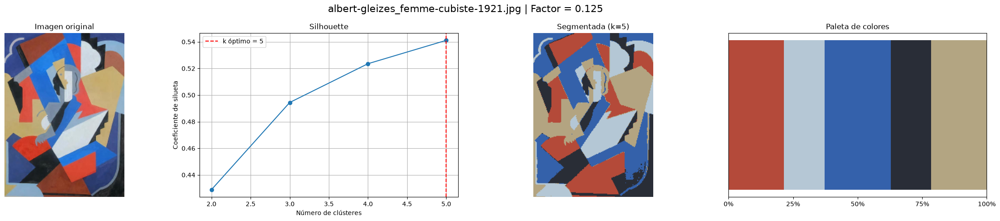

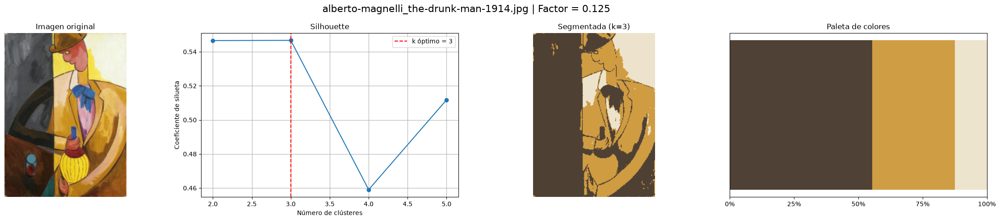

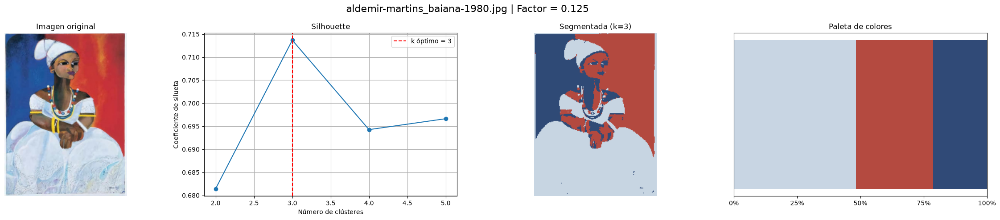

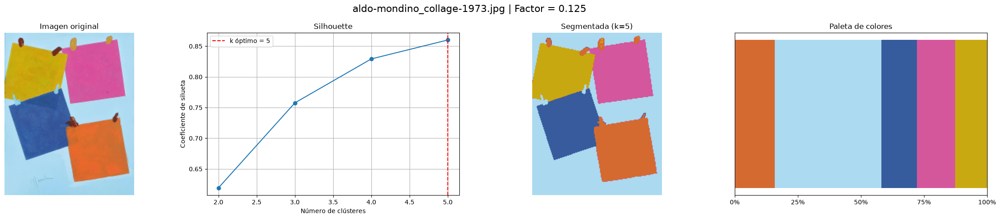

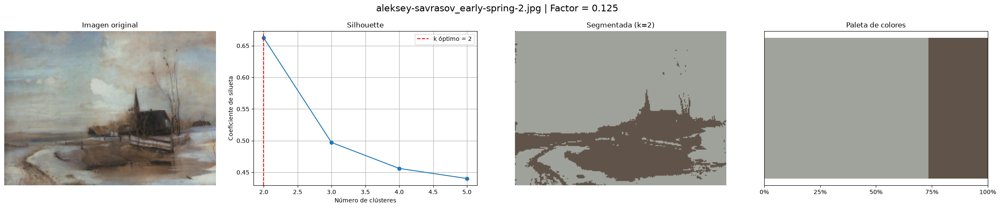

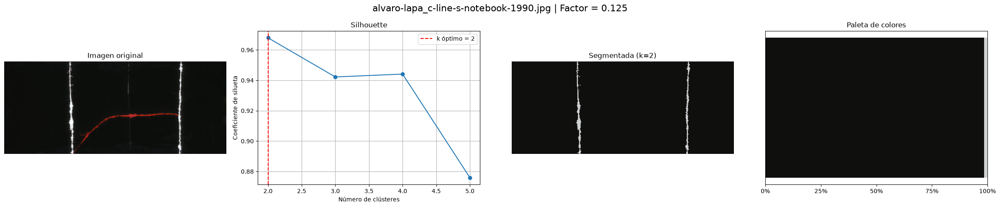

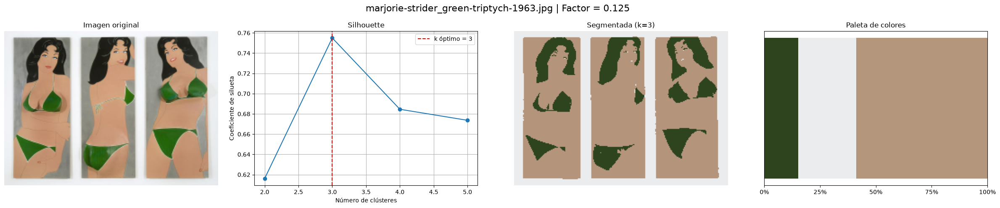

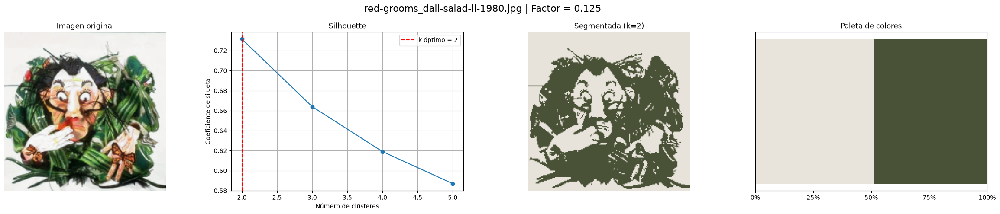

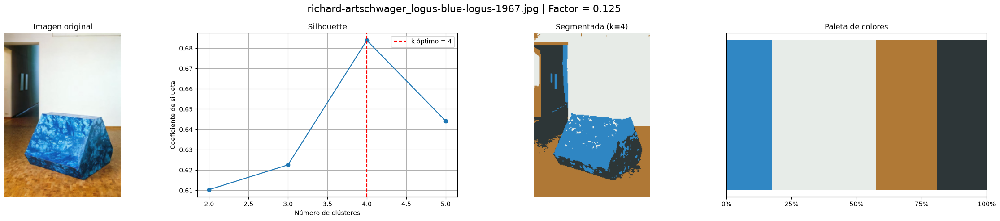

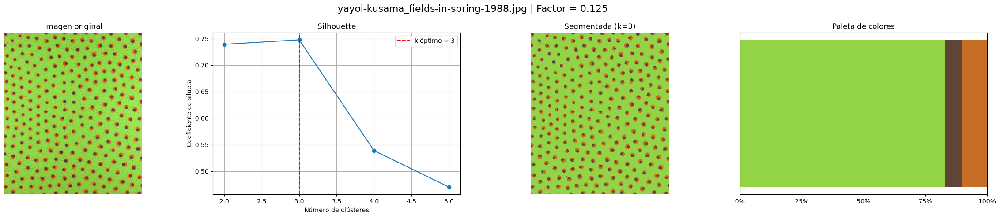

In [31]:
for p in paletas:

    # Extraemos de "paletas" los colores representativos encontrados
    # por K-Means y la etiqueta asignada a cada píxel.
    colores = p["colores"]
    etiquetas = p["etiquetas"]

    r = next(
        x for x in resultados
        if x["path"] == p["path"] and x["factor"] == p["factor"]
    )

    siluetas = r["siluetas"]
    k_optimo = p["k_optimo"]

    
    img_segmentada = (
        colores[etiquetas] * 255
    ).reshape(p["shape"]).astype(np.uint8)

     
    proporciones = np.bincount(etiquetas) / len(etiquetas)
    fig, ax = plt.subplots(1, 4, figsize=(24, 5))

    # 1. Original
    ax[0].imshow(p["resized"])
    ax[0].set_title("Imagen original")
    ax[0].axis("off")

    # 2. Silhouette
    ax[1].plot(
        range(2, 2 + len(siluetas)),
        siluetas,
        marker="o"
    )

    ax[1].axvline(
        k_optimo,
        color="red",
        linestyle="--",
        label=f"k óptimo = {k_optimo}"
    )

    ax[1].set_title("Silhouette")
    ax[1].set_xlabel("Número de clústeres")
    ax[1].set_ylabel("Coeficiente de silueta")
    ax[1].grid()
    ax[1].legend()

    # 3. Segmentada
    ax[2].imshow(img_segmentada)
    ax[2].set_title(f"Segmentada (k={k_optimo})")
    ax[2].axis("off")

    # 4. Paleta
    inicio = 0

    for color, proporcion in zip(colores, proporciones):

        ax[3].barh(
            0,
            proporcion,
            left=inicio,
            color=color
        )

        inicio += proporcion

    ax[3].set_xlim(0, 1)
    ax[3].set_yticks([])
    ax[3].set_xticks([0, 0.25, 0.50, 0.75, 1])
    ax[3].set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax[3].set_title("Paleta de colores")

    fig.suptitle(
        f'{p["path"]} | Factor = {p["factor"]}',
        fontsize=16
    )

    plt.tight_layout()
    plt.show()